<a href="https://colab.research.google.com/github/ckurtz/teaching_UPC_UFRMI/blob/main/CLIP_tutorial_(with_medical_images_ROCO).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Notebook created in 2024 with the help of Xiaoyang Wei, Phd student at LIPADE, Université Paris Cité

# Interacting with CLIP

This is a self-contained notebook that shows how to download and run CLIP models, calculate the similarity between arbitrary image and text inputs, and perform zero-shot image classifications.

# Preparation for Colab

Make sure you're running a GPU runtime; if not, select "GPU" as the hardware accelerator in Runtime > Change Runtime Type in the menu. The next cells will install the `clip` package and its dependencies, and check if PyTorch 1.7.1 or later is installed.

In [ ]:
! pip install ftfy regex tqdm
! pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-szs0pwyb
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-szs0pwyb
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


# Loading the model

`clip.available_models()` will list the names of available CLIP models.

In [ ]:
import clip
import numpy as np

clip.available_models()

['RN50',
 'RN101',
 'RN50x4',
 'RN50x16',
 'RN50x64',
 'ViT-B/32',
 'ViT-B/16',
 'ViT-L/14',
 'ViT-L/14@336px']

In [ ]:
model, preprocess = clip.load("ViT-B/16")
model.cuda().eval()
input_resolution = model.visual.input_resolution
context_length = model.context_length
vocab_size = model.vocab_size

print("Model parameters:", f"{np.sum([int(np.prod(p.shape)) for p in model.parameters()]):,}")
print("Input resolution:", input_resolution)
print("Context length:", context_length)
print("Vocab size:", vocab_size)

100%|████████████████████████████████████████| 335M/335M [00:01<00:00, 229MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


AssertionError: Torch not compiled with CUDA enabled

# Image Preprocessing

We resize the input images and center-crop them to conform with the image resolution that the model expects. Before doing so, we will normalize the pixel intensity using the dataset mean and standard deviation.

The second return value from `clip.load()` contains a torchvision `Transform` that performs this preprocessing.



In [ ]:
preprocess

Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7e3f020ecea0>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)

# Text Preprocessing

We use a case-insensitive tokenizer, which can be invoked using `clip.tokenize()`. By default, the outputs are padded to become 77 tokens long, which is what the CLIP models expects.

In [ ]:
clip.tokenize("Hello World!")

tensor([[49406,  3306,  1002,   256, 49407,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0]], dtype=torch.int32)

# Setting up input images and texts

We are going to feed 8 example natrural/medical images and their textual descriptions to the model, and compare the similarity between the corresponding features.

The tokenizer is case-insensitive, and we can freely give any suitable textual descriptions.

In [ ]:
import os
import skimage
import IPython.display
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from collections import OrderedDict
import torch

%matplotlib inline
%config InlineBackend.figure_format = 'retina'


# to mount google drive
if os.getcwd()=='/content':
    try:
        from google.colab import drive
        base_working_dir = '/content/drive/MyDrive'
        drive.mount('/content/drive')
    except:
        base_working_dir = os.getcwd()
        pass
!mkdir -p drive
!google-drive-ocamlfuse drive
print(base_working_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/bin/bash: line 1: google-drive-ocamlfuse: command not found
/content/drive/MyDrive


In [ ]:
# images to use and their textual descriptions
descriptions = {
    "page": "a page of text about segmentation",
    "chelsea": "a facial photo of a tabby cat",
    "astronaut": "a portrait of an astronaut with the American flag",
    "rocket": "a rocket standing on a launchpad",
    "motorcycle_right": "a red motorcycle standing in a garage",
    "camera": "a person looking at a camera on a tripod",
    "horse": "a black-and-white silhouette of a horse",
    "coffee": "a cup of coffee on a saucer"
}

med_descriptions = {
    "ROCO_00002": "CT scan in axial view showing obliteration of the left maxillary sinus",
    "ROCO_00017": "Coronary angiogram demonstrating occluded arteries",
    "ROCO_00028": "T2 weighted MRI image showing foraminal extensions of the cysts",
    "ROCO_00033": "Lytic lesions (arrows) involving the humerus.",
    "ROCO_00050": "Free air beneath the diaphragm at abdominal x-ray film",
    "ROCO_00056": "View of giant cell tumor of thumb metacarpal preoperatively",
    "ROCO_00060": "Transverse view of lung using CT.Leukemic infiltration is seen.",
    "ROCO_00135": "CT scan showing multiple non-communicating cysts in liver and kidney"
}

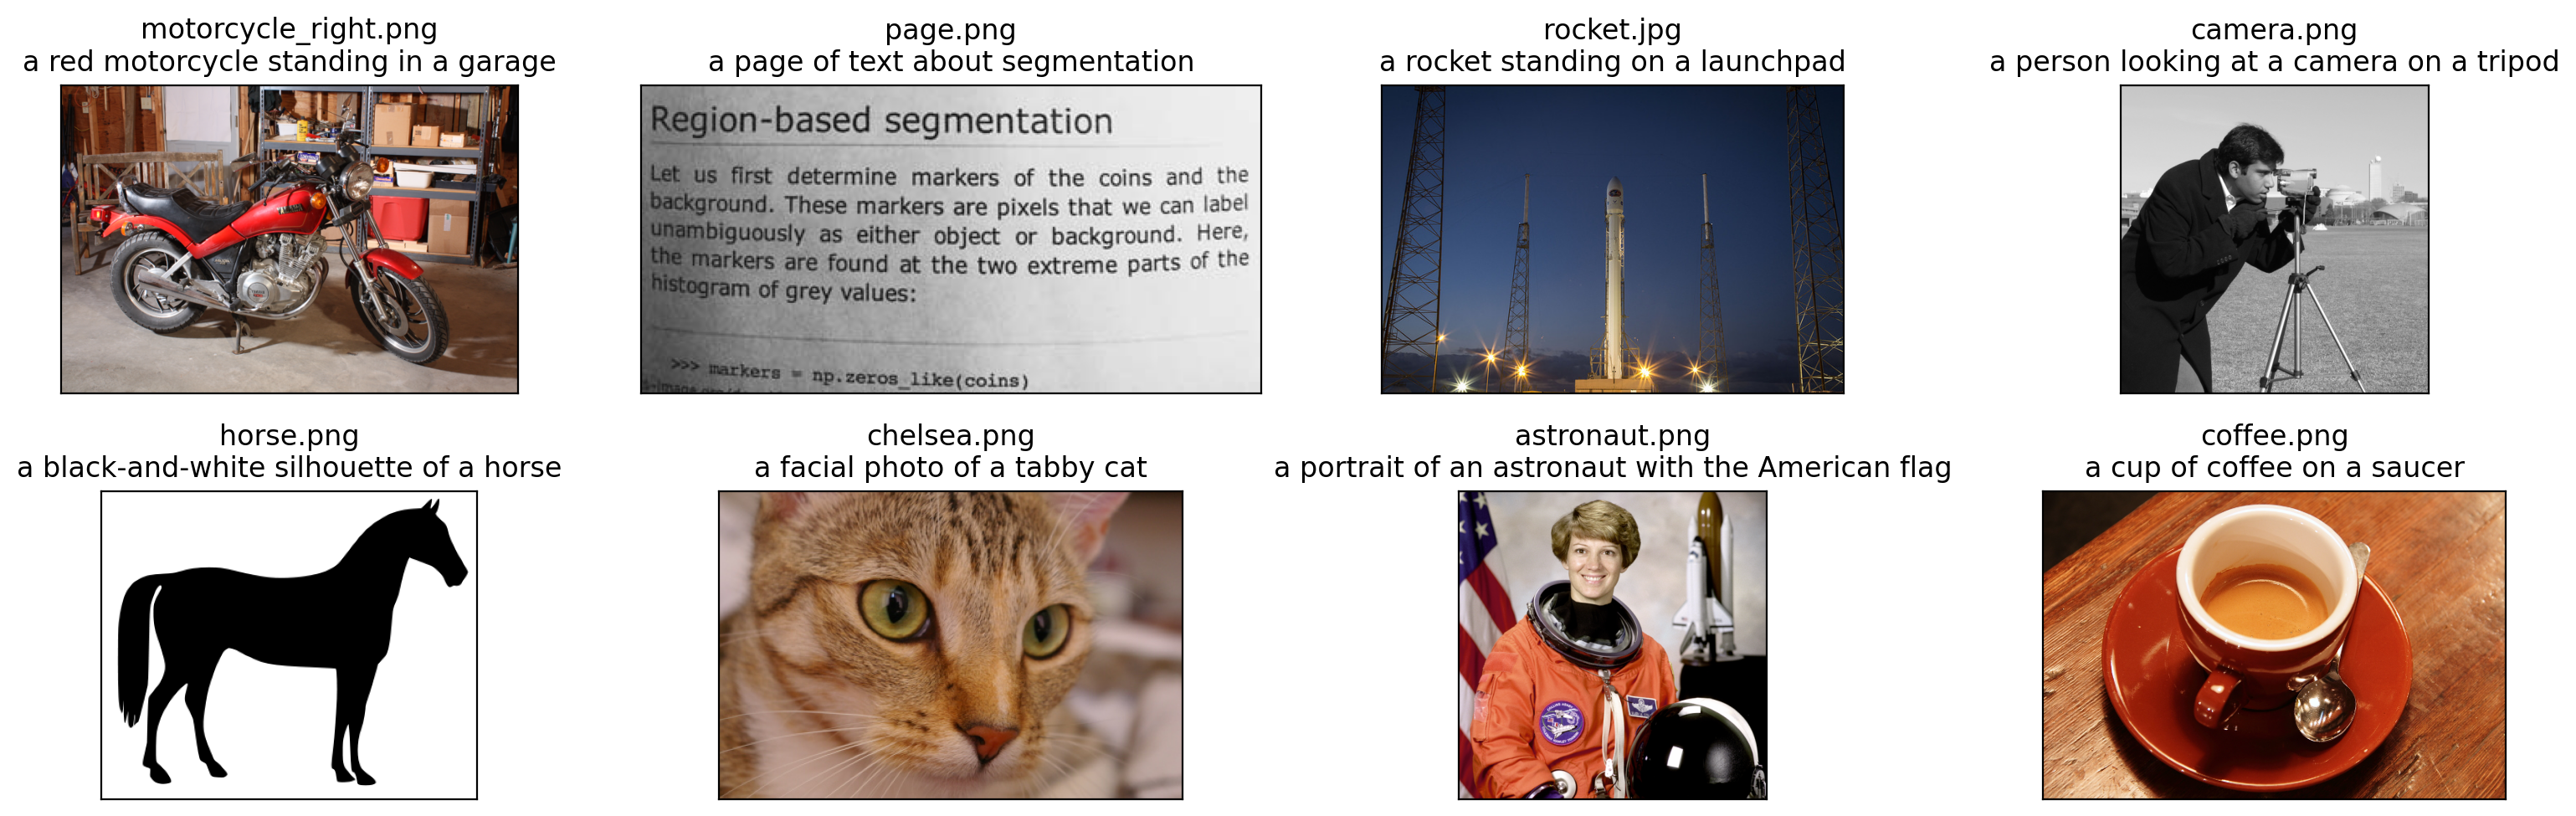

In [ ]:
original_images = []
images = []
texts = []
plt.figure(figsize=(16, 5))

skimage.data.download_all(directory=None)
for filename in [filename for filename in os.listdir(skimage.data_dir) if filename.endswith(".png") or filename.endswith(".jpg")]:
    name = os.path.splitext(filename)[0]
    if name not in descriptions:
        continue

    image = Image.open(os.path.join(skimage.data_dir, filename)).convert("RGB")

    plt.subplot(2, 4, len(images) + 1)
    plt.imshow(image)
    plt.title(f"{filename}\n{descriptions[name]}")
    plt.xticks([])
    plt.yticks([])

    original_images.append(image)
    images.append(preprocess(image))
    texts.append(descriptions[name])

plt.tight_layout()


## Building features

We normalize the images, tokenize each text input, and run the forward pass of the model to get the image and text features.

In [ ]:
image_input = torch.tensor(np.stack(images)).to(device)
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).to(device)
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()

## Calculating cosine similarity

We normalize the features and calculate the dot product of each pair.

Text(0.5, 1.0, 'Cosine similarity between text and image features(natural)')

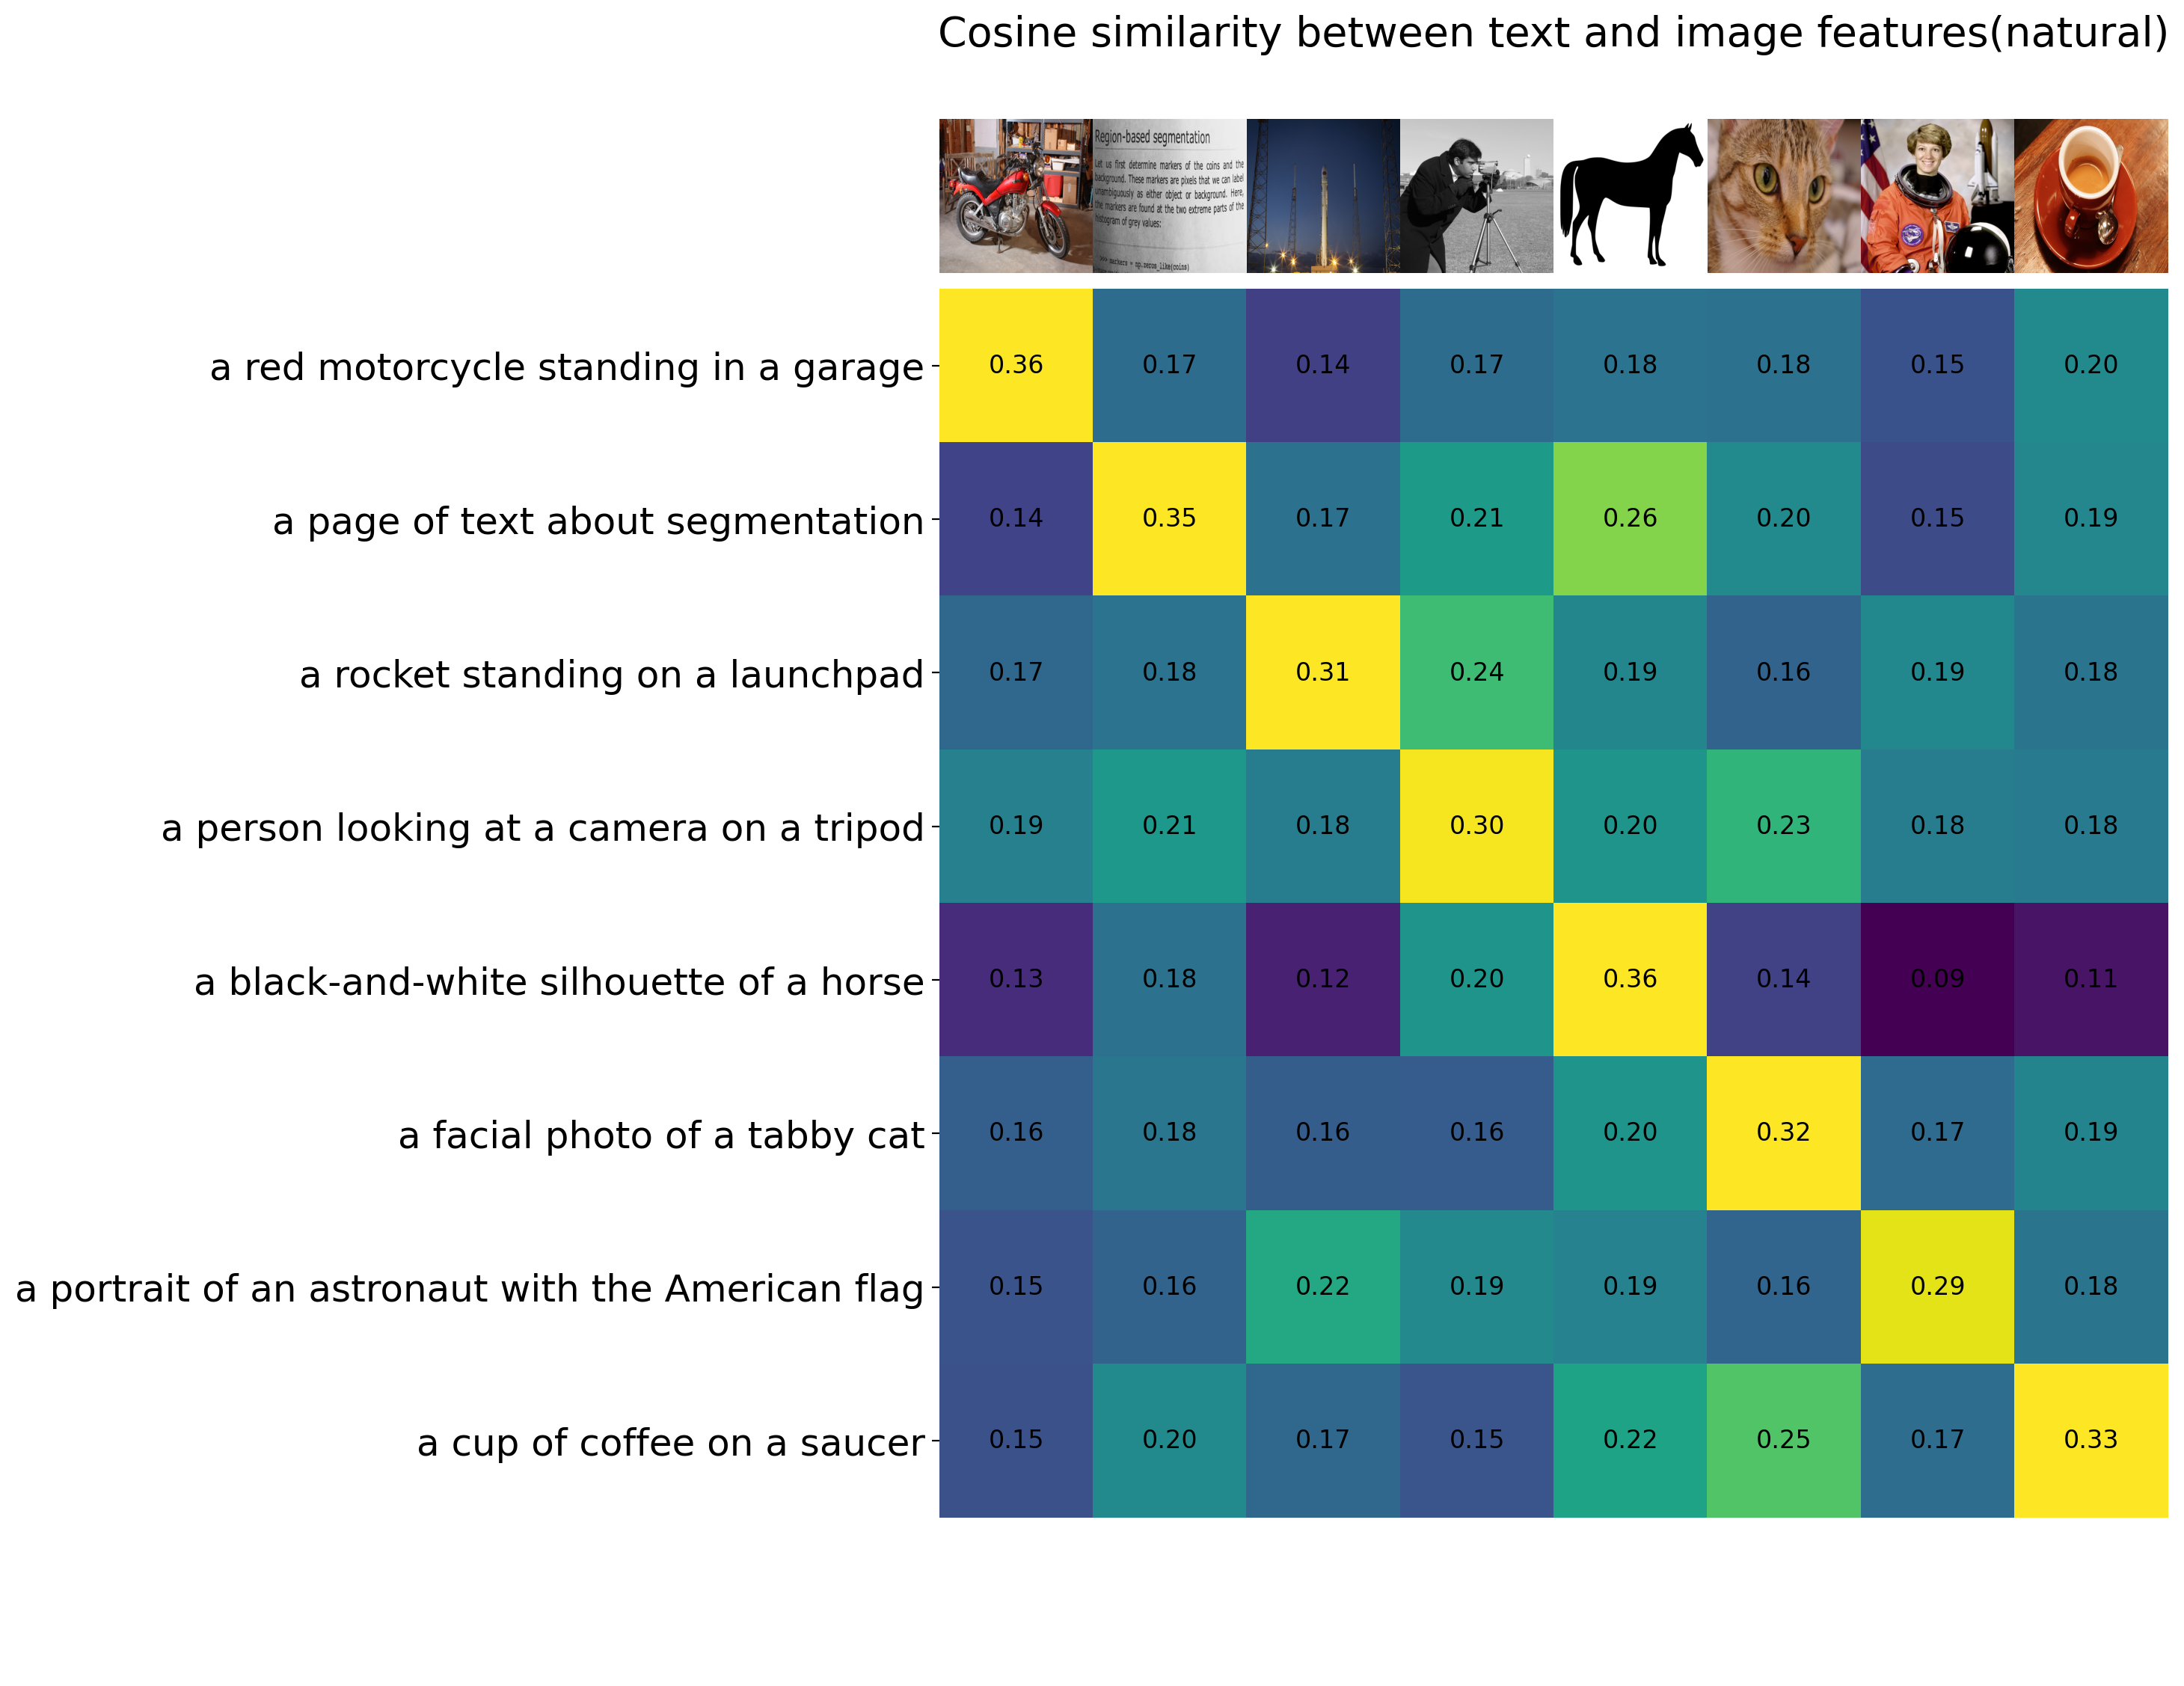

In [ ]:
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
# plt.colorbar()
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)

for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(natural)", size=20)

## Performance of CLIP in medical domain

In [ ]:
original_images = []
images = []
texts = []
for filename in list(med_descriptions.keys()):
    image = Image.open(os.path.join("/content/drive/My Drive/data/pretrain_data/roco/train/radiology/images", filename+'.jpg'))
    original_images.append(image)
    images.append(preprocess(image))
    texts.append(med_descriptions[filename])
image_input = torch.tensor(np.stack(images)).cuda()
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
# plt.colorbar()
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)
for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(medical)", size=20)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/My Drive/data/pretrain_data/roco/train/radiology/images/ROCO_00002.jpg'

# Zero-Shot Image Classification

You can classify images using the cosine similarity (times 100) as the logits to the softmax operation.

In [ ]:
from torchvision.datasets import CIFAR100

cifar100 = CIFAR100(os.path.expanduser("~/.cache"), transform=preprocess, download=True)

100%|██████████| 169M/169M [24:18<00:00, 116kB/s]


In [ ]:
text_descriptions = [f"This is a photo of a {label}" for label in cifar100.classes]
text_tokens = clip.tokenize(text_descriptions).cuda()

In [ ]:
with torch.no_grad():
    text_features = model.encode_text(text_tokens).float()
    text_features /= text_features.norm(dim=-1, keepdim=True)

text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)
top_probs, top_labels = text_probs.cpu().topk(5, dim=-1)

In [ ]:
plt.figure(figsize=(16, 16))

for i, image in enumerate(original_images):
    plt.subplot(4, 4, 2 * i + 1)
    plt.imshow(image)
    plt.axis("off")

    plt.subplot(4, 4, 2 * i + 2)
    y = np.arange(top_probs.shape[-1])
    plt.grid()
    plt.barh(y, top_probs[i])
    plt.gca().invert_yaxis()
    plt.gca().set_axisbelow(True)
    plt.yticks(y, [cifar100.classes[index] for index in top_labels[i].numpy()])
    plt.xlabel("probability")

plt.subplots_adjust(wspace=0.5)
plt.show()

# Fine-tuning CLIP on ROCO



In [ ]:
csv_file ="/content/drive/My Drive/data/roco-list.csv"
root_dir = "/content/drive/My Drive/data/pretrain_data/roco/train/radiology/images"
val_csv_file = "/content/drive/My Drive/data/local-val-list.csv"
val_root_dir = "/content/drive/My Drive/data/pretrain_data/roco/val/radiology/images"

# train options
seed = 42
batch_size = 16
image_size = 224
start_epoch = 0
epochs = 10
visual_encoder = "clip@ViT-B/16"
learning_rate = 3e-6
model_path = "/content/drive/My Drive/model_checkpoint_CLIP_ROCO"


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import datetime
import time
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
from torch.utils.data import Dataset
import random
import clip



class CLRDataset(Dataset):
    """Contrastive Learning Representations Dataset."""

    def __init__(self, csv_file, root_dir, transform=None, clip=False):
        self.clr_frame = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform
        self.clip = clip

    def __len__(self):
        return len(self.clr_frame)

    def text_sampling(self, text):
        text = text.replace("\n", " ")
        text = text.split(".")
        if '' in text:
            text.remove('')
        text = random.choice(text)
        return text

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        img_name = os.path.join(self.root_dir,
                                self.clr_frame.iloc[idx, 0]
                                )
        if not os.path.exists(img_name):
            img_name=img_name.replace('train','val')
        image = Image.open(img_name)
        if not self.clip:
            image = image.convert('RGB')
        text = self.clr_frame.iloc[idx, 1]
        name = self.clr_frame.iloc[idx, 0]
        sample = {'image': image, 'text': text,'name':name}
        if self.clip:
            sample = self.transform(sample['image']), sample['text'],sample['name']
        elif self.transform:
            sample = self.transform(sample)

        return sample


def load_optimizer( model, lr=3e-6):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, epochs, eta_min=0, last_epoch=-1
    )
    return optimizer, scheduler


def train( train_loader, model, tokenizer, optimizer,truncation):
    loss_epoch = 0
    for step, (images, texts,name) in enumerate(train_loader):
        optimizer.zero_grad()
        x_v = images.to('cuda')
        x_u = tokenizer(list(texts), truncate=True).to('cuda')

        v,u=model(x_v,x_u)

        labels = torch.arange(batch_size, dtype=torch.long, device='cuda')

        loss_img = torch.nn.CrossEntropyLoss()
        loss_txt = torch.nn.CrossEntropyLoss()

        img_loss = loss_img(v,labels)
        text_loss = loss_txt(u,labels)

        loss = (img_loss + text_loss)/2

        loss.backward()
        optimizer.step()

        if step % 500 == 0:
            print(f"Step [{step}/{len(train_loader)}]\t Loss: {loss.item()}")

        loss_epoch += loss.item()
    return loss_epoch



def validate( val_loader, model, tokenizer, optimizer, truncation):

    with torch.no_grad():
        model.eval()
        loss_epoch = 0
        for step, (x_v, x_u) in enumerate(val_loader):
            x_v = x_v.to('cuda')
            x_u = tokenizer(list(x_u), truncate=True).to('cuda')

            v,u=model(x_v,x_u)

            labels = torch.arange(batch_size, dtype=torch.long, device='cuda')

            loss_img = torch.nn.CrossEntropyLoss()
            loss_txt = torch.nn.CrossEntropyLoss()

            img_loss = loss_img(v,labels)
            text_loss = loss_txt(u,labels)

            loss = (img_loss + text_loss)/2
            loss_epoch += loss.item()

    model.train()
    return loss_epoch


def main(gpu):

    is_master=True
    torch.cuda.set_device(gpu) # mise sur CPU pour le deuxième TEST
    torch.manual_seed(seed)
    np.random.seed(seed)

    print("Initializing model... ", end="", flush=True)
    model, preprocess = clip.load(visual_encoder.split("@")[-1], device='cuda', jit=False)
    model.float()
    tokenizer=clip.tokenize
    train_fonction = train
    validate_fonction = validate

    optimizer, scheduler = load_optimizer(model, lr=float(learning_rate))

    # initialize dataloader
    transform = preprocess
    print('Image_Transform',transform)
    train_dataset = CLRDataset(csv_file=csv_file,
                               root_dir=root_dir,
                               transform=transform,
                               clip = True
                               )

    val_dataset = CLRDataset(csv_file=val_csv_file,
                             root_dir=val_root_dir,
                             transform=transform,
                             clip = True
                             )

    train_sampler = None
    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=(train_sampler is None),
        drop_last=True,
        num_workers=8,
        sampler=train_sampler,
    )

    val_loader = torch.utils.data.DataLoader(
        val_dataset,
        batch_size=batch_size,
        drop_last=True,
        num_workers=8
    )

    print("[DONE]\n")
    print("STARTING TRAINING")
    print('Start Time =', datetime.datetime.now().strftime("%H:%M:%S"), '\n')

    t0 = time.time()
    global_step = 0
    current_epoch = 0
    best_val_loss = np.inf

    for epoch in range(0, epochs):
        if epoch<2:
            if train_sampler is not None:
                train_sampler.set_epoch(epoch)

            lr = optimizer.param_groups[0]["lr"]
            loss_epoch = train_fonction(train_loader, model, tokenizer, optimizer,True)

        if is_master:
            val_loss = validate_fonction( val_loader, model, tokenizer, optimizer, True)
            if val_loss < best_val_loss:
                torch.save(model.state_dict(), os.path.join(model_path, "best_checkpoint.pth"))
                best_val_loss = val_loss

            epoch_counter = epoch - 0
            elapsed = time.time() - t0
            epoch_time = elapsed/(epoch_counter+1)
            remaining = (epochs - (epoch_counter+1))*epoch_time
            remaining = str(datetime.timedelta(seconds=round(remaining)))
            elapsed = str(datetime.timedelta(seconds=round(elapsed)))
            print(f'Epoch {epoch_counter+1}/{epochs} [{elapsed}<{remaining}, {round(epoch_time, 2)}s/epoch] {round((epoch_counter+1)/epochs*100, 1)}% loss: {loss_epoch / len(train_loader)}\t val_loss: {val_loss / len(val_loader)} lr: {lr}')

            current_epoch += 1


if not os.path.exists(model_path):
    os.makedirs(model_path)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", device)
main(0)

Device: cuda:0
Initializing model... 

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Image_Transform Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7e6db324d4e0>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)
[DONE]

STARTING TRAINING
Start Time = 14:49:53 



/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Step [0/4087]	 Loss: 1.6037722826004028
Step [500/4087]	 Loss: 0.9689518213272095
Step [1000/4087]	 Loss: 1.0434527397155762
Step [1500/4087]	 Loss: 0.828583836555481
Step [2000/4087]	 Loss: 0.7248810529708862
Step [2500/4087]	 Loss: 0.6749132871627808
Step [3000/4087]	 Loss: 0.5112448930740356
Step [3500/4087]	 Loss: 0.6103990077972412
Step [4000/4087]	 Loss: 0.33668291568756104


ValueError: too many values to unpack (expected 2)

## Performance of CLIP in medical domain(after fine-tuning on ROCO )

Text(0.5, 1.0, 'Cosine similarity between text and image features(medical)')

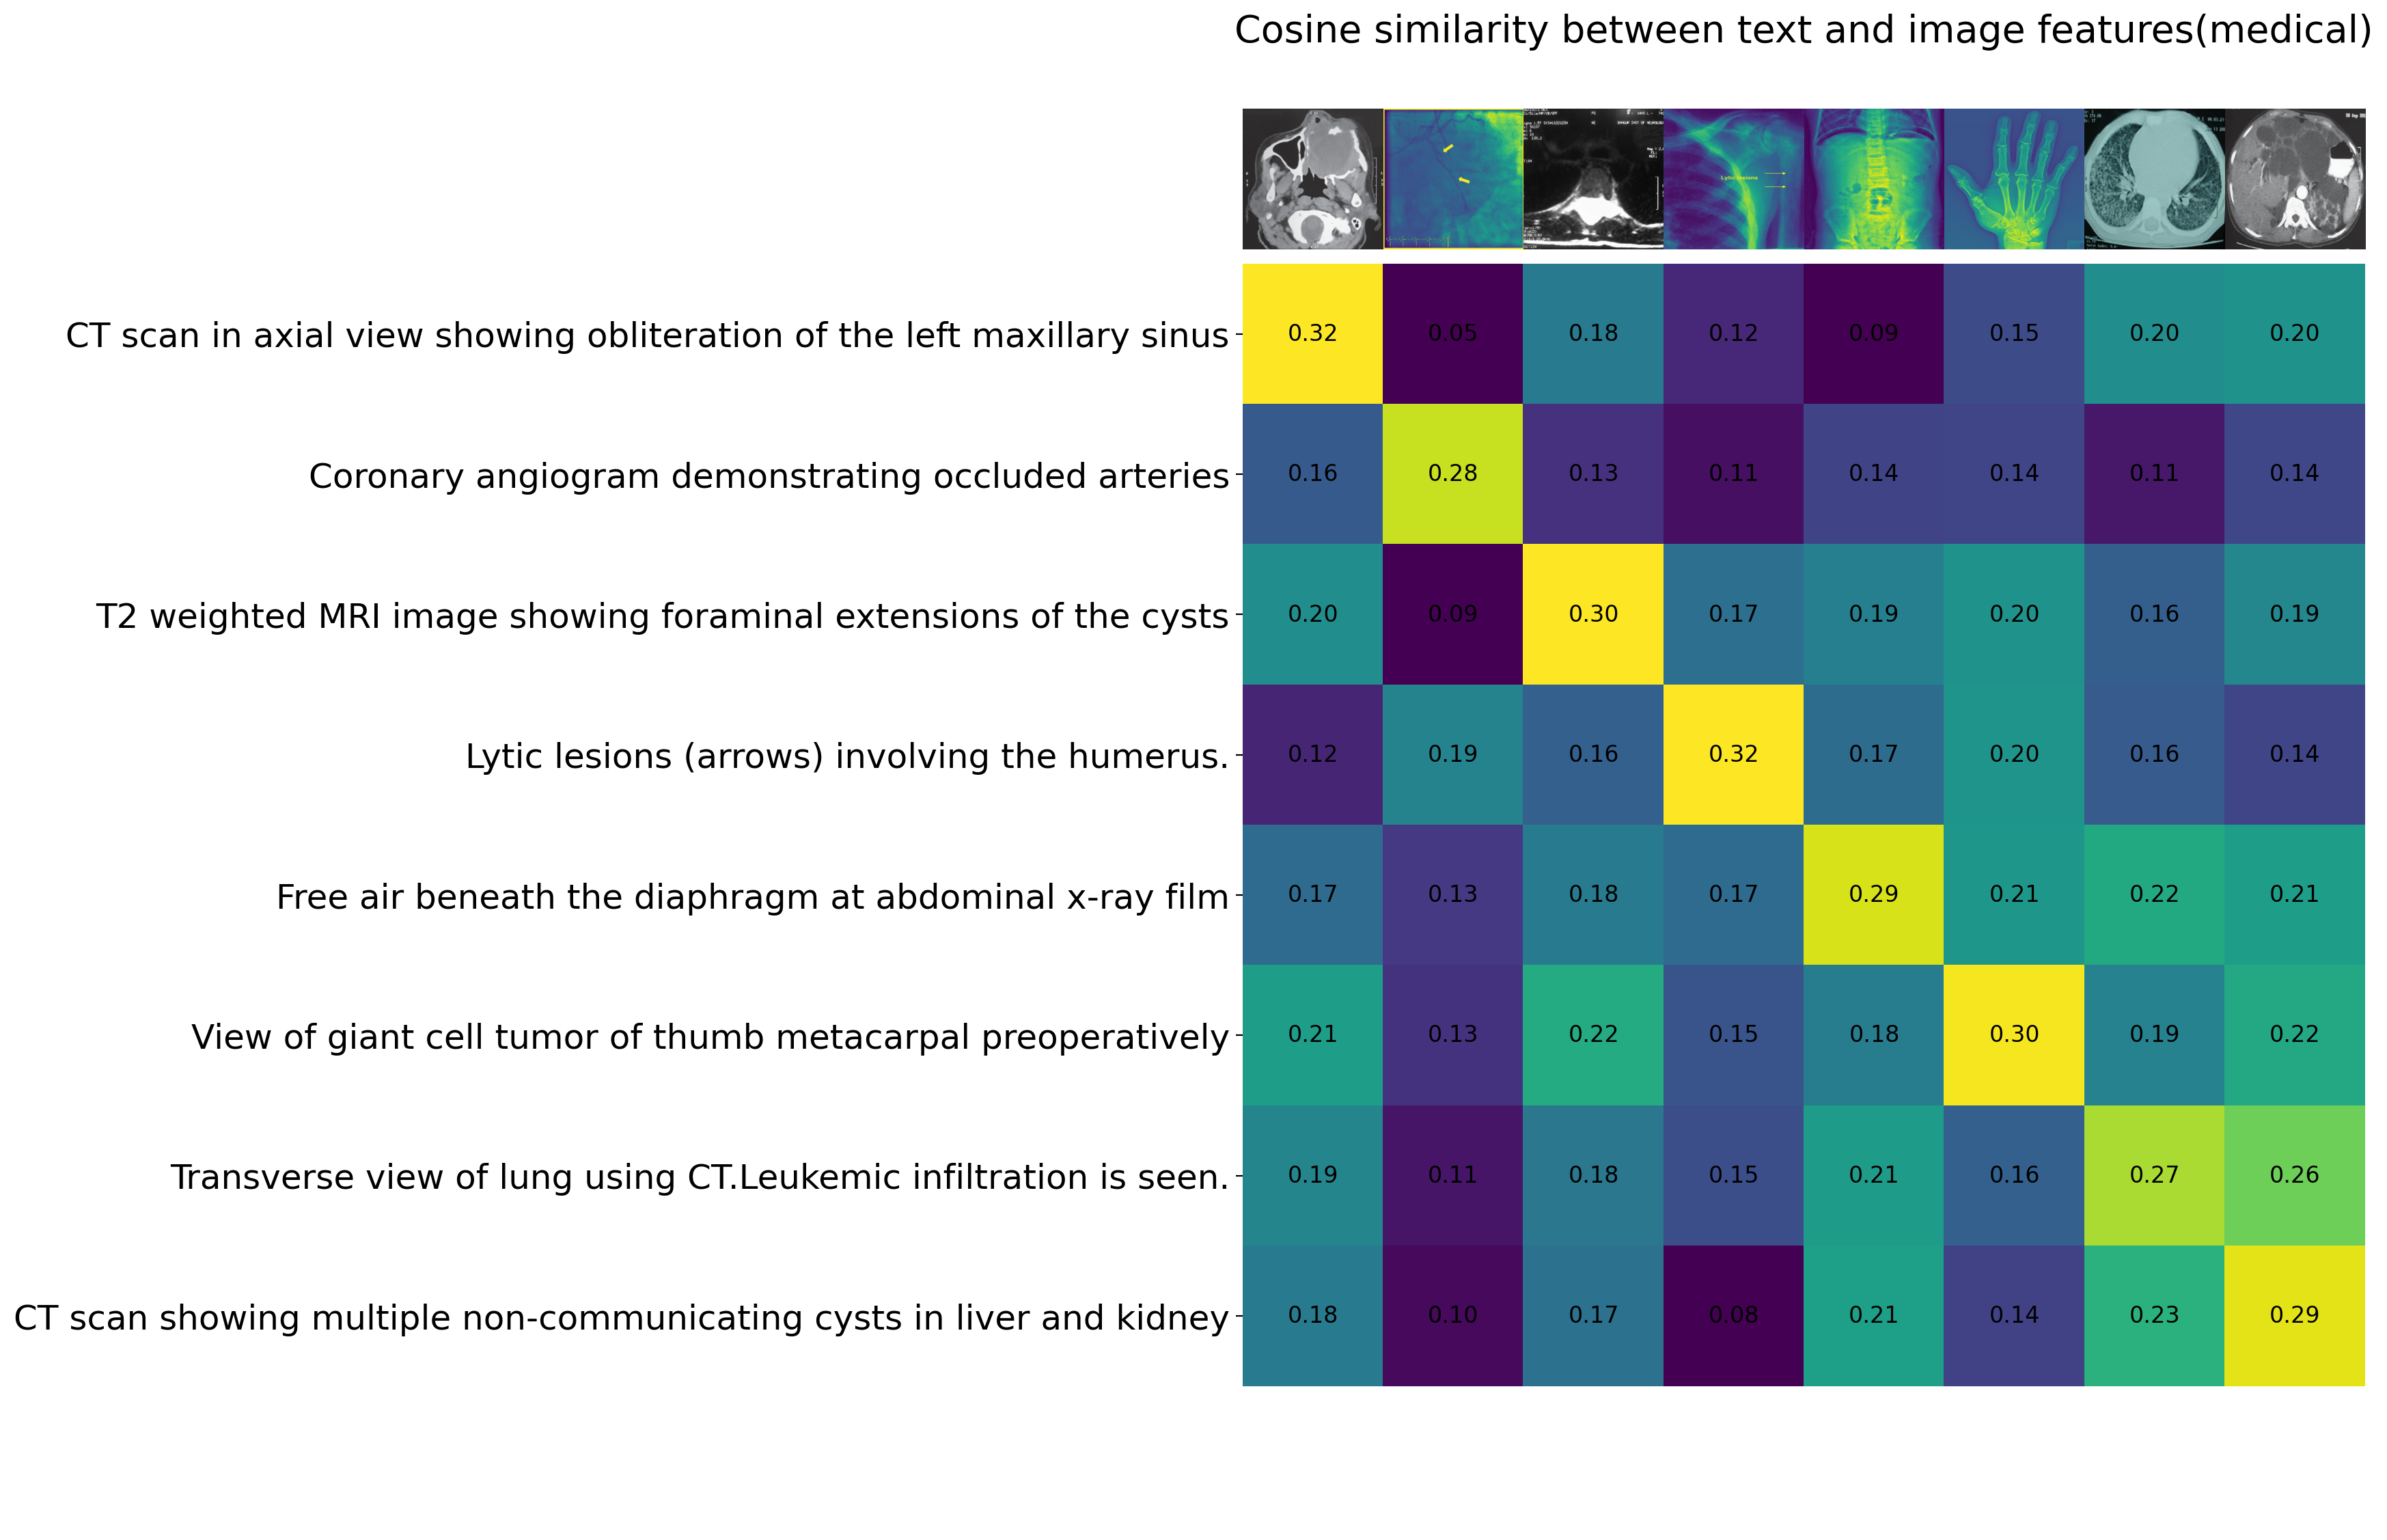

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device).float().eval()

ckpt = torch.load('/content/drive/My Drive/data/ViT-B-16_best_checkpoint_2.tar', map_location=device)
if isinstance(ckpt, dict):
    state_dict = ckpt.get("state_dict") or ckpt.get("model_state_dict") or ckpt
    model.load_state_dict(state_dict, strict=False)
else:
    model.load_state_dict(ckpt, strict=False)

original_images = []
images = []
texts = []
for filename in list(med_descriptions.keys()):
    image = Image.open(os.path.join("/content/drive/My Drive/data/pretrain_data/roco/train/radiology/images", filename+'.jpg'))
    original_images.append(image)
    images.append(preprocess(image))
    texts.append(med_descriptions[filename])

image_input = torch.tensor(np.stack(images)).to(device)
text_tokens = clip.tokenize(["This is " + desc for desc in texts], truncate=True).to(device)

with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()

image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)

for side in ["left", "top", "right", "bottom"]:
    plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(medical)", size=20)

In [ ]:
import time
import torch
import clip
import numpy as np
import pandas as pd
from torchvision.datasets import CIFAR100
from torch.utils.data import DataLoader, Subset
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
models_to_eval = ["RN50", "RN101", "ViT-B/32", "ViT-B/16", "ViT-L/14"]
n_samples = 1000 # Résonnable pour l'utilisation du CPU, sinon le temps d'évaluation est trop long

cifar100_test_raw = CIFAR100(root="~/.cache", train=False, download=True)
classes = cifar100_test_raw.classes
prompts = [f"This is a photo of a {label}" for label in classes]
text_tokens = clip.tokenize(prompts).to(device)

rng = np.random.default_rng(42)
subset_indices = rng.choice(len(cifar100_test_raw), size=min(n_samples, len(cifar100_test_raw)), replace=False).tolist()

results = []

for model_name in models_to_eval:
    print(f"\n--- Évaluation de {model_name} ({len(subset_indices)} images sur {device}) ---")
    model, preprocess = clip.load(model_name, device=device, jit=False)
    model = model.float().eval()

    num_params = sum(p.numel() for p in model.parameters()) / 1e6
    res = model.visual.input_resolution

    full_dataset = CIFAR100(root="~/.cache", train=False, transform=preprocess, download=False)
    dataset = Subset(full_dataset, subset_indices)
    loader = DataLoader(dataset, batch_size=128, shuffle=False, num_workers=2)

    with torch.no_grad():
        text_features = model.encode_text(text_tokens).float()
        text_features /= text_features.norm(dim=-1, keepdim=True)

    top1_correct = 0
    top5_correct = 0
    total = 0

    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()

    with torch.no_grad():
        for images, labels in tqdm(loader, leave=False):
            images = images.to(device)
            labels = labels.to(device)

            image_features = model.encode_image(images).float()
            image_features /= image_features.norm(dim=-1, keepdim=True)

            logits = 100.0 * (image_features @ text_features.T)
            _, pred_top5 = logits.topk(5, dim=-1, largest=True, sorted=True)

            total += labels.size(0)
            top1_correct += (pred_top5[:, 0] == labels).sum().item()
            top5_correct += (pred_top5 == labels.unsqueeze(1)).any(dim=-1).sum().item()

    if device == "cuda":
        torch.cuda.synchronize()
    elapsed = time.time() - t0

    top1_acc = 100.0 * top1_correct / total
    top5_acc = 100.0 * top5_correct / total

    results.append({
        "Modèle": model_name,
        "Paramètres (M)": round(num_params, 1),
        "Résolution": f"{res}x{res}",
        "Top-1 Acc (%)": round(top1_acc, 2),
        "Top-5 Acc (%)": round(top5_acc, 2),
        "Temps inférence (s)": round(elapsed, 2)
    })
    print(f"{model_name} -> Top-1: {top1_acc:.2f}% | Top-5: {top5_acc:.2f}% | Temps: {elapsed:.2f}s")

    del model
    if device == "cuda":
        torch.cuda.empty_cache()

df_results = pd.DataFrame(results)
df_results.to_csv("/content/drive/MyDrive/clip_models_benchmark_subset.csv", index=False)
display(df_results)


--- Évaluation de RN50 (1000 images sur cpu) ---


RN50 -> Top-1: 40.80% | Top-5: 72.20% | Temps: 339.43s

--- Évaluation de RN101 (1000 images sur cpu) ---


100%|███████████████████████████████████████| 278M/278M [00:18<00:00, 15.9MiB/s]


RN101 -> Top-1: 44.20% | Top-5: 73.80% | Temps: 490.41s

--- Évaluation de ViT-B/32 (1000 images sur cpu) ---


100%|███████████████████████████████████████| 338M/338M [00:06<00:00, 51.5MiB/s]


ViT-B/32 -> Top-1: 60.30% | Top-5: 86.60% | Temps: 173.44s

--- Évaluation de ViT-B/16 (1000 images sur cpu) ---


ViT-B/16 -> Top-1: 65.50% | Top-5: 86.70% | Temps: 769.19s

--- Évaluation de ViT-L/14 (1000 images sur cpu) ---


100%|████████████████████████████████████████| 890M/890M [00:03<00:00, 251MiB/s]


ViT-L/14 -> Top-1: 72.20% | Top-5: 91.80% | Temps: 3212.45s


,Modèle,Paramètres (M),Résolution,Top-1 Acc (%),Top-5 Acc (%),Temps inférence (s)
0,RN50,102.0,224x224,40.8,72.2,339.43
1,RN101,119.7,224x224,44.2,73.8,490.41
2,ViT-B/32,151.3,224x224,60.3,86.6,173.44
3,ViT-B/16,149.6,224x224,65.5,86.7,769.19
4,ViT-L/14,427.6,224x224,72.2,91.8,3212.45


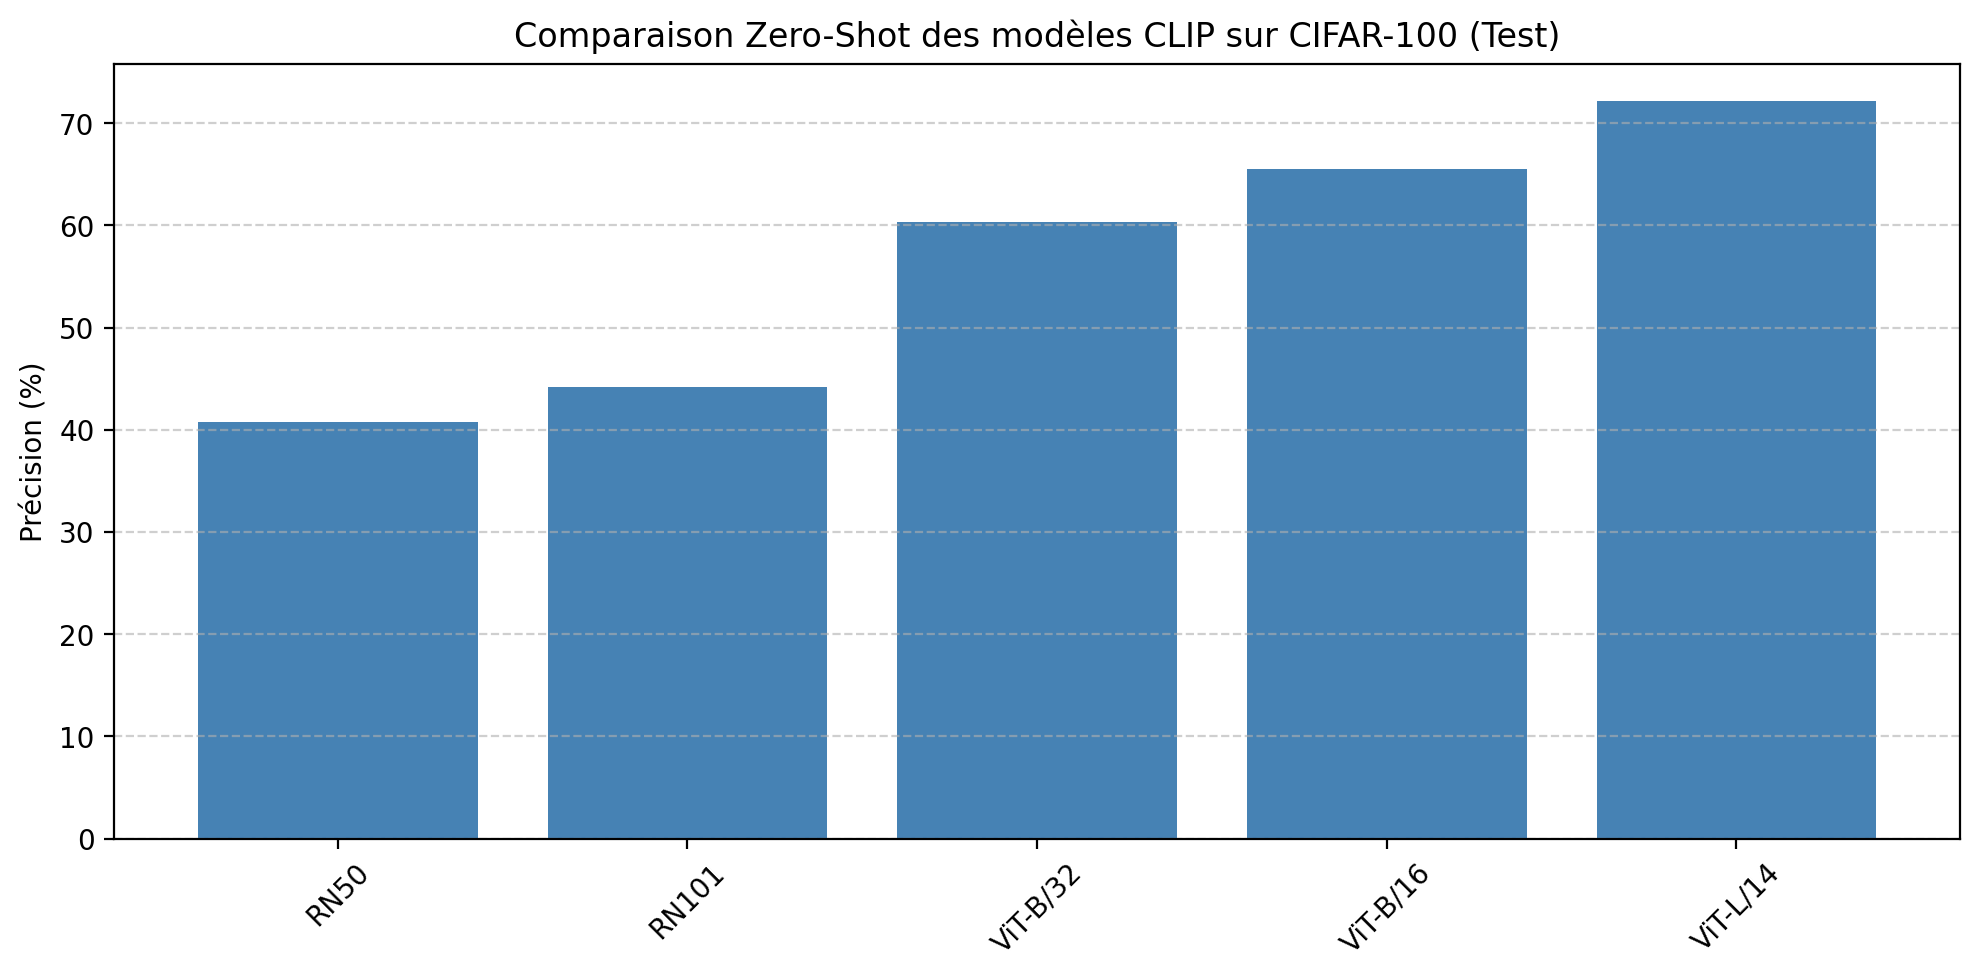

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(df_results["Modèle"], df_results["Top-1 Acc (%)"], color="steelblue", label="Top-1 Accuracy")
plt.xticks(rotation=45)
plt.ylabel("Précision (%)")
plt.title("Comparaison Zero-Shot des modèles CLIP sur CIFAR-100 (Test)")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Nombre d'entrées dans local-val-list.csv : 8173


,A,B
0,ROCO_00020.jpg,Axial computed tomography scan of the pelvis s...
1,ROCO_00027.jpg,Postoperative anteroposterior radiograph of th...
2,ROCO_00059.jpg,"Angiography of the internal carotid artery, la..."


Exemples sélectionnés : ['ROCO_40549', 'ROCO_08640', 'ROCO_59498', 'ROCO_41116', 'ROCO_44938', 'ROCO_19950', 'ROCO_39753', 'ROCO_73393']


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


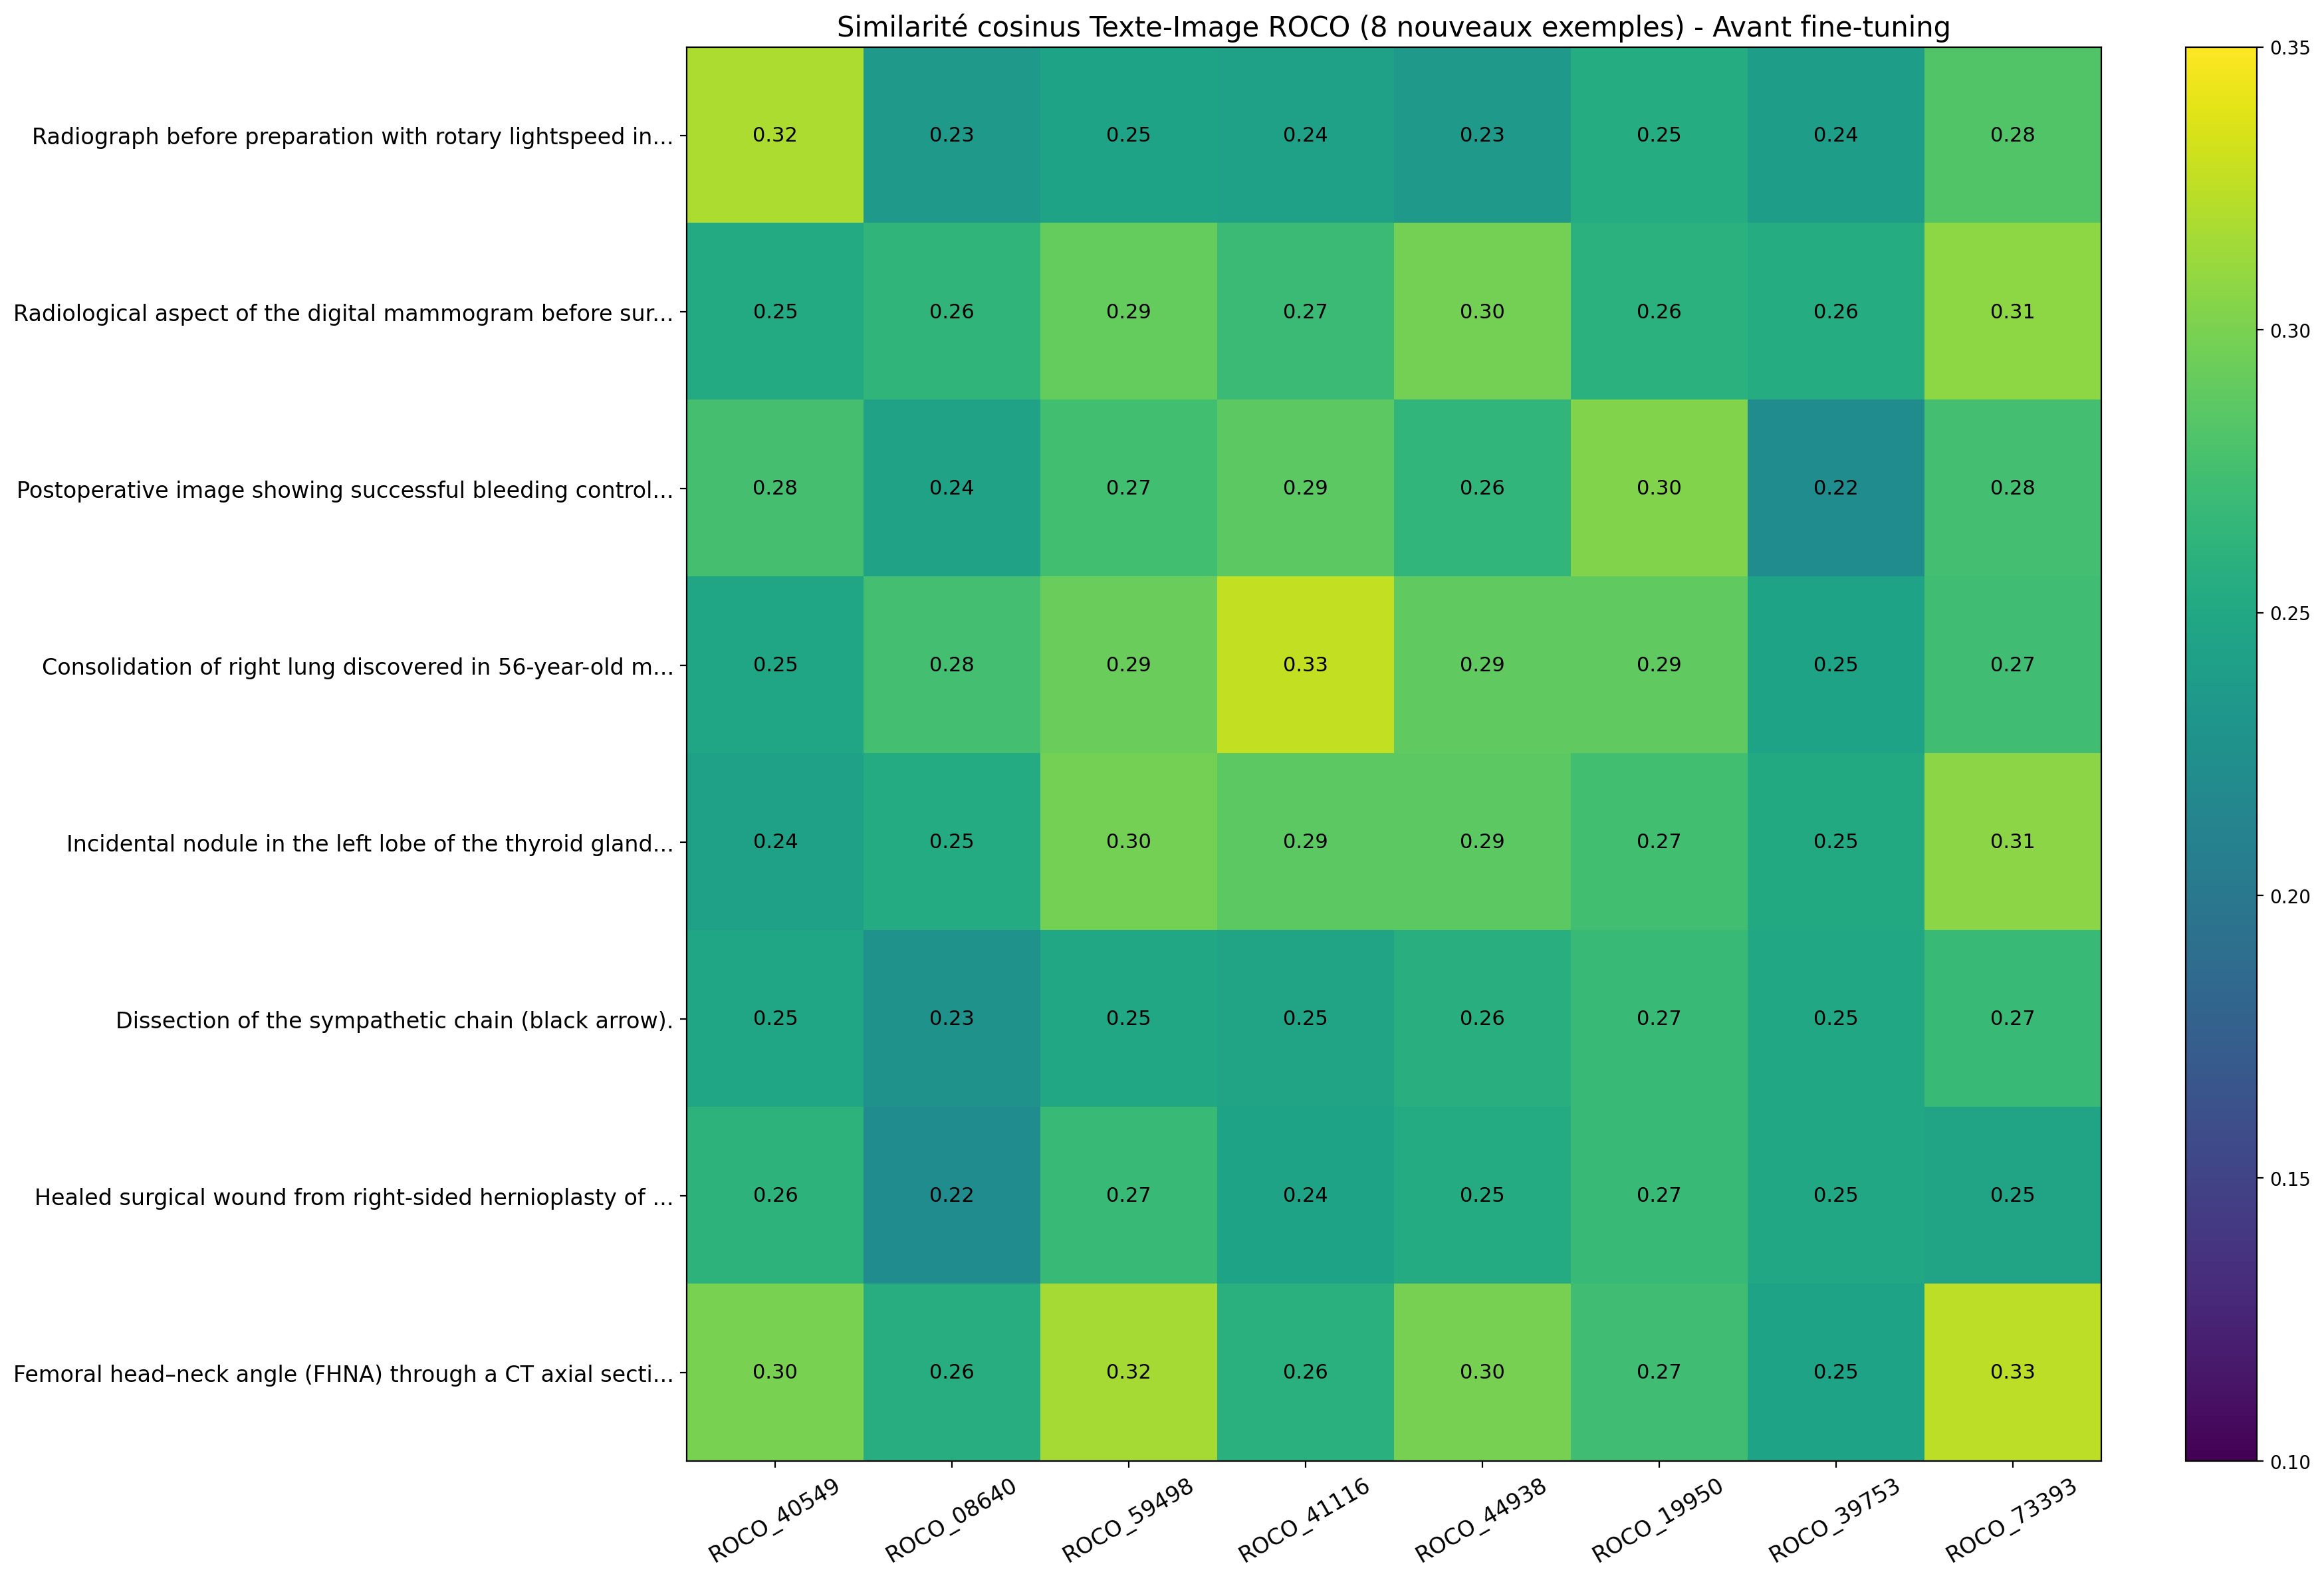

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


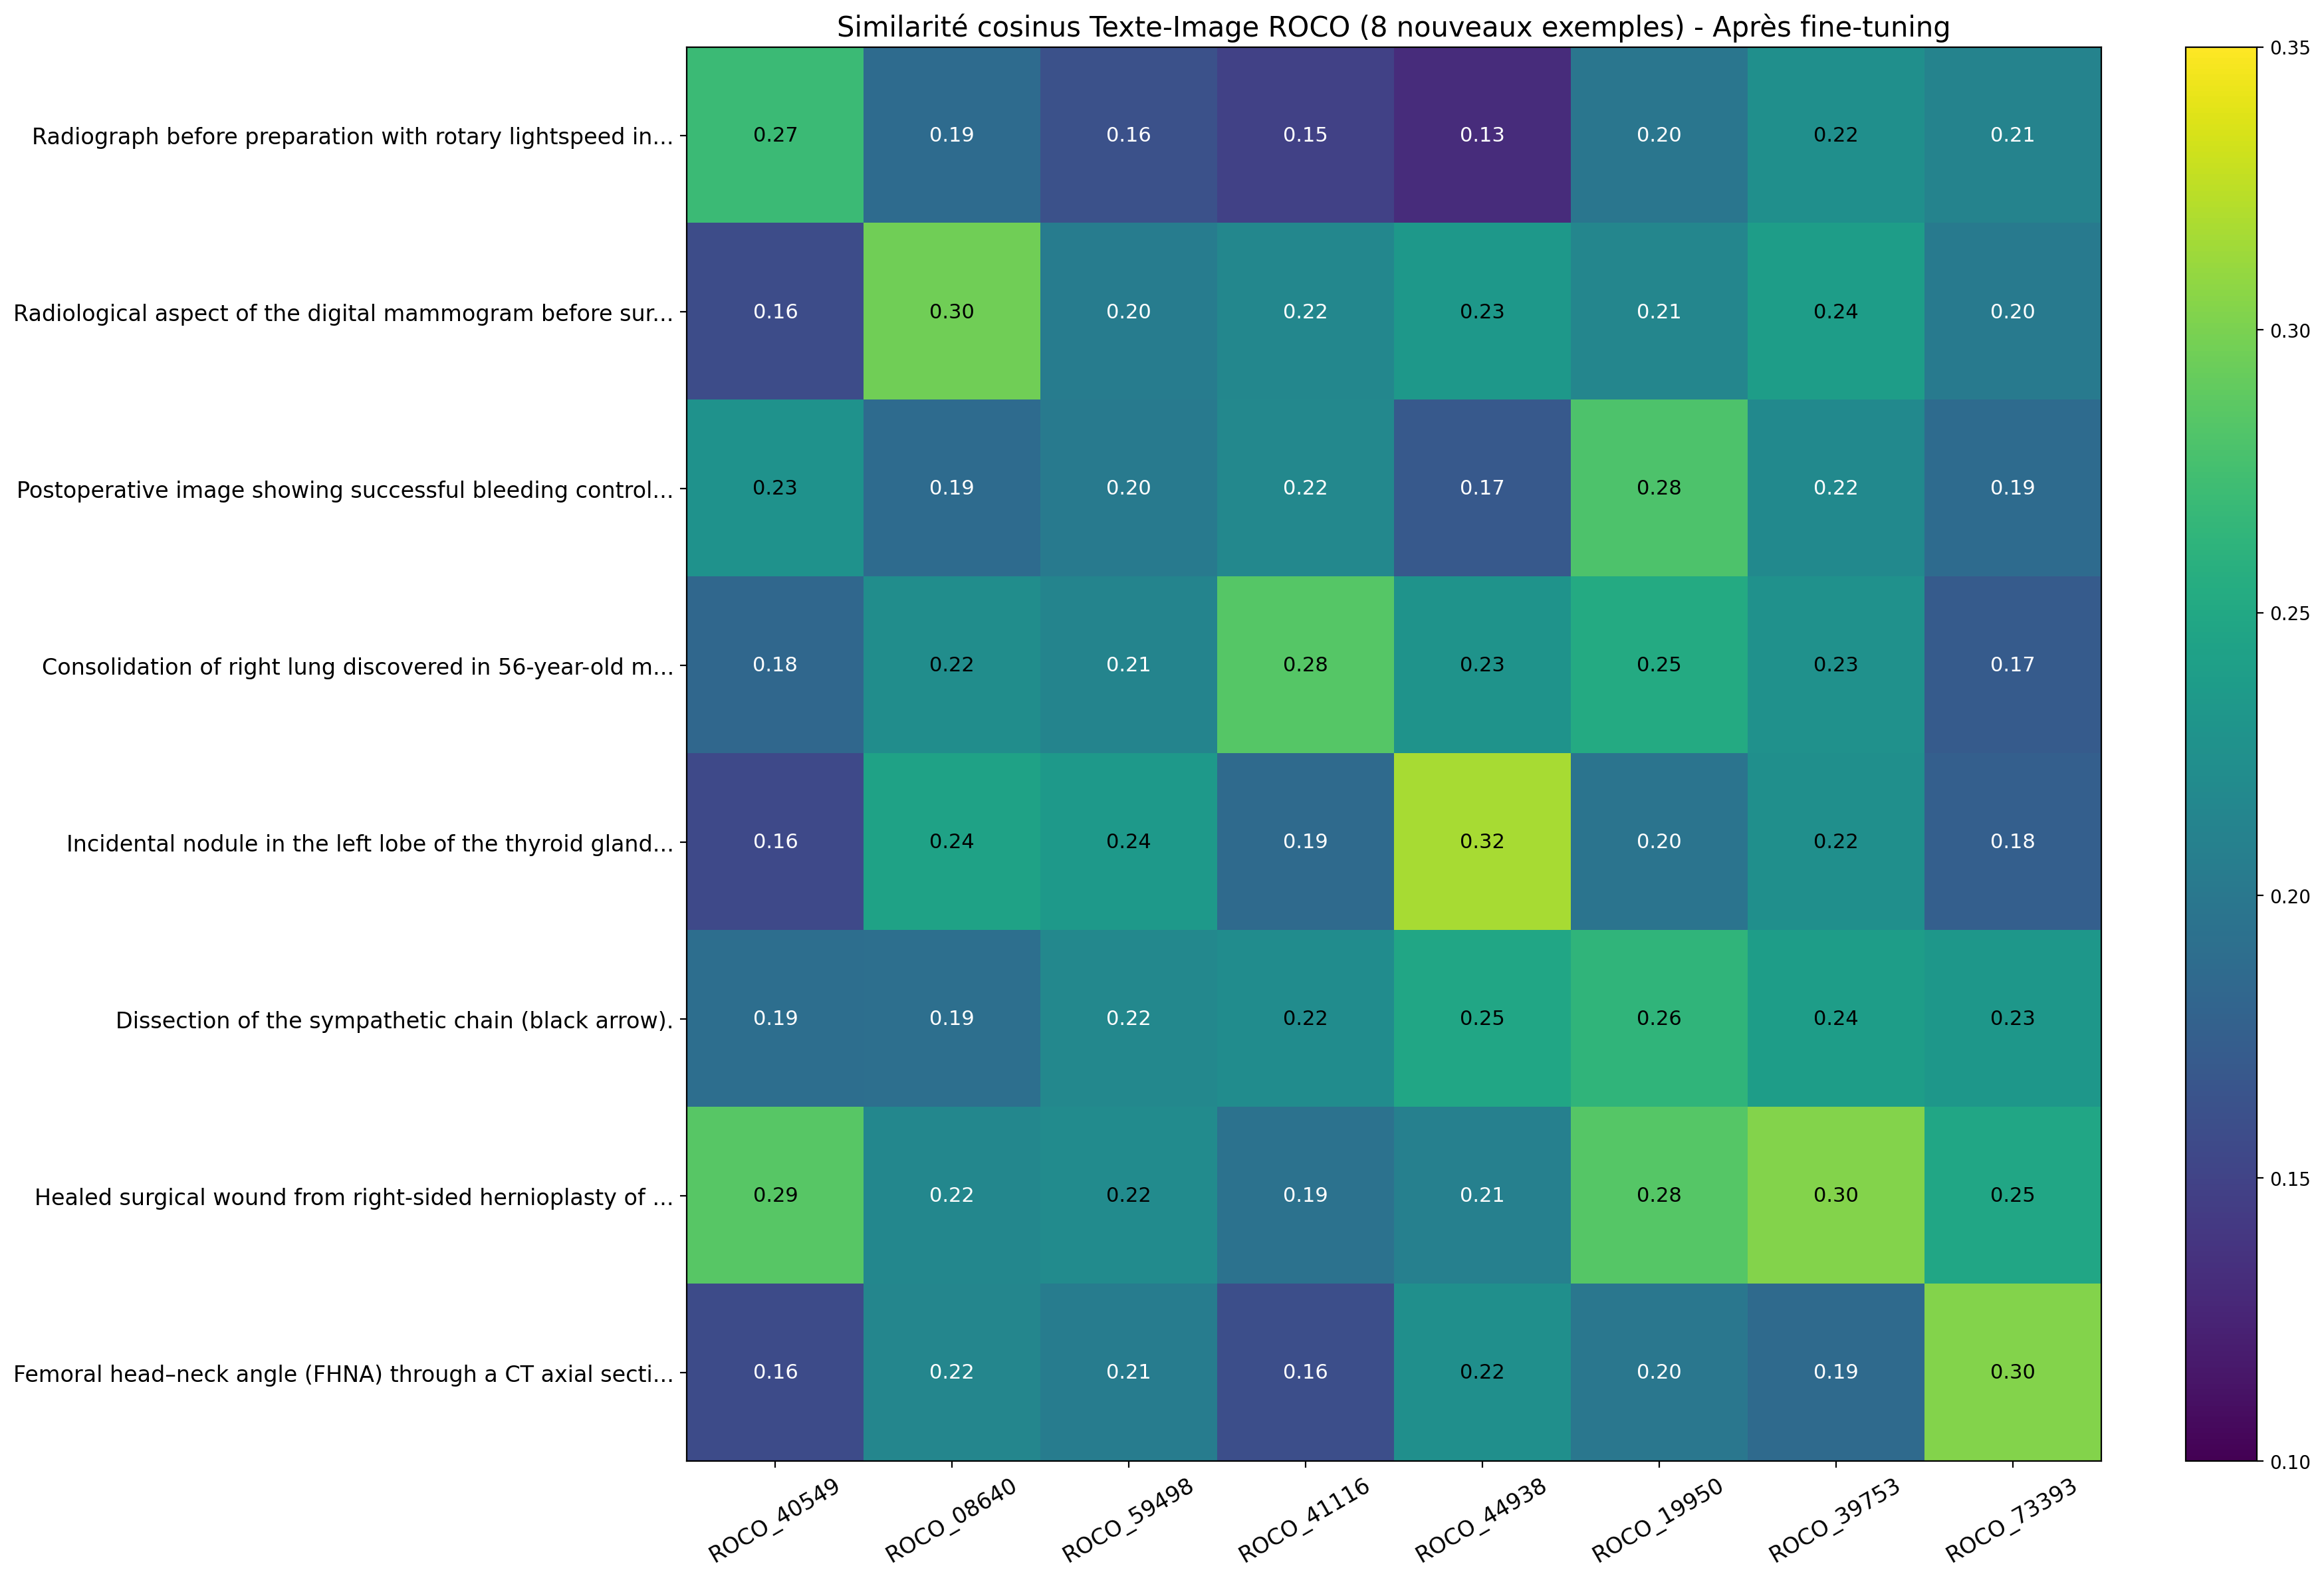


Sur 50 paires ROCO :
Avant fine-tuning -> Image-to-Text R@1: 30.0% | Text-to-Image R@1: 34.0%
Après fine-tuning -> Image-to-Text R@1: 56.0% | Text-to-Image R@1: 68.0%


In [ ]:
import os
import random
import pandas as pd
import numpy as np
import torch
import clip
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True
device = "cuda" if torch.cuda.is_available() else "cpu"

base_data = "/content/drive/My Drive/data"
val_csv = os.path.join(base_data, "local-val-list.csv")
val_img_dir = os.path.join(base_data, "pretrain_data/roco/val/radiology/images")
train_img_dir = os.path.join(base_data, "pretrain_data/roco/train/radiology/images")
ckpt_path = os.path.join(base_data, "ViT-B-16_best_checkpoint_2.tar")

df_val = pd.read_csv(val_csv)
print("Nombre d'entrées dans local-val-list.csv :", len(df_val))
display(df_val.head(3))

def resolve_img_path(fname):
    for d in [val_img_dir, train_img_dir]:
        p = os.path.join(d, str(fname))
        if os.path.exists(p):
            return p
        if not str(fname).lower().endswith((".jpg", ".jpeg", ".png")) and os.path.exists(p + ".jpg"):
            return p + ".jpg"
    return None

# Sélection de 8 nouveaux exemples valides
excluded = {"ROCO_00002", "ROCO_00017", "ROCO_00028", "ROCO_00033", "ROCO_00050", "ROCO_00056", "ROCO_00060", "ROCO_00135"}
random.seed(123)

samples = []
indices = list(range(len(df_val)))
random.shuffle(indices)

for idx in indices:
    fname = str(df_val.iloc[idx, 0])
    caption = str(df_val.iloc[idx, 1]).strip()
    stem = os.path.splitext(fname)[0]
    if stem in excluded or not caption or caption == "nan":
        continue
    path = resolve_img_path(fname)
    if path is not None:
        try:
            im = Image.open(path).convert("RGB")
            samples.append((stem, im, caption))
        except Exception:
            continue
    if len(samples) == 8:
        break

print("Exemples sélectionnés :", [s[0] for s in samples])

def compute_sim_matrix(mdl, sample_list):
    imgs_t = torch.stack([preprocess(s[1]) for s in sample_list]).to(device)
    txts_t = clip.tokenize(["This is " + s[2] for s in sample_list], truncate=True).to(device)
    with torch.no_grad():
        img_f = mdl.encode_image(imgs_t).float()
        txt_f = mdl.encode_text(txts_t).float()
        img_f /= img_f.norm(dim=-1, keepdim=True)
        txt_f /= txt_f.norm(dim=-1, keepdim=True)
    return (txt_f @ img_f.T).cpu().numpy()

def plot_med_similarity(sim, sample_list, title):
    n = len(sample_list)
    short_texts = [s[2][:55] + ("..." if len(s[2]) > 55 else "") for s in sample_list]
    plt.figure(figsize=(18, 12))
    plt.imshow(sim, vmin=0.1, vmax=0.35, cmap="viridis")
    plt.yticks(range(n), short_texts, fontsize=12)
    plt.xticks(range(n), [s[0] for s in sample_list], fontsize=12, rotation=30)
    for x in range(sim.shape[1]):
        for y in range(sim.shape[0]):
            val = sim[y, x]
            color = "black" if val > 0.22 else "white"
            plt.text(x, y, f"{val:.2f}", ha="center", va="center", size=11, color=color)
    plt.colorbar(fraction=0.046, pad=0.04)
    plt.title(title, fontsize=15)
    plt.tight_layout()
    plt.show()

# Modèle de base (sans fine-tuning ROCO)
base_model, _ = clip.load("ViT-B/16", device=device, jit=False)
base_model.float().eval()
sim_before = compute_sim_matrix(base_model, samples)
plot_med_similarity(sim_before, samples, "Similarité cosinus Texte-Image ROCO (8 nouveaux exemples) - Avant fine-tuning")

# Chargement du checkpoint fine-tuné sur ROCO
ft_model, _ = clip.load("ViT-B/16", device=device, jit=False)
ft_model.float()
ckpt = torch.load(ckpt_path, map_location=device)
state_dict = ckpt["state_dict"] if isinstance(ckpt, dict) and "state_dict" in ckpt else ckpt
ft_model.load_state_dict(state_dict, strict=False)
ft_model.eval()

sim_after = compute_sim_matrix(ft_model, samples)
plot_med_similarity(sim_after, samples, "Similarité cosinus Texte-Image ROCO (8 nouveaux exemples) - Après fine-tuning")

# Évaluation quantitative rapide (Recall) sur 50 paires valides
eval_pairs = []
for idx in indices:
    fname = str(df_val.iloc[idx, 0])
    caption = str(df_val.iloc[idx, 1]).strip()
    if not caption or caption == "nan":
        continue
    path = resolve_img_path(fname)
    if path is not None:
        try:
            im = Image.open(path).convert("RGB")
            eval_pairs.append((im, caption))
        except Exception:
            continue
    if len(eval_pairs) == 50:
        break

def eval_retrieval_r1(mdl, pairs):
    imgs_t = torch.stack([preprocess(p[0]) for p in pairs]).to(device)
    txts_t = clip.tokenize(["This is " + p[1] for p in pairs], truncate=True).to(device)
    with torch.no_grad():
        img_f = mdl.encode_image(imgs_t).float()
        txt_f = mdl.encode_text(txts_t).float()
        img_f /= img_f.norm(dim=-1, keepdim=True)
        txt_f /= txt_f.norm(dim=-1, keepdim=True)
        # sim_i2t[i, j] = similarité entre image i et texte j
        sim_i2t = img_f @ txt_f.T
        i2t_pred = sim_i2t.argmax(dim=-1)
        t2i_pred = sim_i2t.T.argmax(dim=-1)
        gt = torch.arange(len(pairs), device=device)
        r1_i2t = (i2t_pred == gt).float().mean().item() * 100
        r1_t2i = (t2i_pred == gt).float().mean().item() * 100
    return r1_i2t, r1_t2i

b_i2t, b_t2i = eval_retrieval_r1(base_model, eval_pairs)
f_i2t, f_t2i = eval_retrieval_r1(ft_model, eval_pairs)

print(f"\nSur {len(eval_pairs)} paires ROCO :")
print(f"Avant fine-tuning -> Image-to-Text R@1: {b_i2t:.1f}% | Text-to-Image R@1: {b_t2i:.1f}%")
print(f"Après fine-tuning -> Image-to-Text R@1: {f_i2t:.1f}% | Text-to-Image R@1: {f_t2i:.1f}%")

In [ ]:
import time
import torch
import clip
import numpy as np
import pandas as pd
from torchvision.datasets import STL10
from torch.utils.data import DataLoader, Subset
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
models_to_eval = ["RN50", "RN101", "ViT-B/32", "ViT-B/16", "ViT-L/14"]
n_samples = 1000

# Jeu de test STL-10
stl10_test_raw = STL10(root="~/.cache", split="test", download=True)
classes = list(stl10_test_raw.classes)
prompts = [f"This is a photo of a {label}" for label in classes]
text_tokens = clip.tokenize(prompts).to(device)

rng = np.random.default_rng(42)
subset_indices = rng.choice(len(stl10_test_raw), size=min(n_samples, len(stl10_test_raw)), replace=False).tolist()

results_stl10 = []

for model_name in models_to_eval:
    print(f"\n--- Évaluation STL-10 de {model_name} ({len(subset_indices)} images sur {device}) ---")
    model, preprocess = clip.load(model_name, device=device, jit=False)
    model = model.float().eval()

    full_dataset = STL10(root="~/.cache", split="test", transform=preprocess, download=False)
    dataset = Subset(full_dataset, subset_indices)
    loader = DataLoader(dataset, batch_size=128, shuffle=False, num_workers=2)

    with torch.no_grad():
        text_features = model.encode_text(text_tokens).float()
        text_features /= text_features.norm(dim=-1, keepdim=True)

    top1_correct = 0
    top5_correct = 0
    total = 0

    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()

    with torch.no_grad():
        for images, labels in tqdm(loader, leave=False):
            images = images.to(device)
            labels = labels.to(device)

            image_features = model.encode_image(images).float()
            image_features /= image_features.norm(dim=-1, keepdim=True)

            logits = 100.0 * (image_features @ text_features.T)
            _, pred_top5 = logits.topk(5, dim=-1, largest=True, sorted=True)

            total += labels.size(0)
            top1_correct += (pred_top5[:, 0] == labels).sum().item()
            top5_correct += (pred_top5 == labels.unsqueeze(1)).any(dim=-1).sum().item()

    if device == "cuda":
        torch.cuda.synchronize()
    elapsed = time.time() - t0

    top1_acc = 100.0 * top1_correct / total
    top5_acc = 100.0 * top5_correct / total

    results_stl10.append({
        "Modèle": model_name,
        "Top-1 Acc (%)": round(top1_acc, 2),
        "Top-5 Acc (%)": round(top5_acc, 2),
        "Temps inférence (s)": round(elapsed, 2)
    })
    print(f"{model_name} -> Top-1: {top1_acc:.2f}% | Top-5: {top5_acc:.2f}% | Temps: {elapsed:.2f}s")

    del model
    if device == "cuda":
        torch.cuda.empty_cache()

df_stl10 = pd.DataFrame(results_stl10)
df_stl10.to_csv("/content/drive/MyDrive/clip_stl10_benchmark_subset.csv", index=False)
display(df_stl10)

100%|██████████| 2.64G/2.64G [03:09<00:00, 14.0MB/s]



--- Évaluation STL-10 de RN50 (1000 images sur cpu) ---


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


RN50 -> Top-1: 95.30% | Top-5: 100.00% | Temps: 345.16s

--- Évaluation STL-10 de RN101 (1000 images sur cpu) ---


RN101 -> Top-1: 96.30% | Top-5: 100.00% | Temps: 513.82s

--- Évaluation STL-10 de ViT-B/32 (1000 images sur cpu) ---


ViT-B/32 -> Top-1: 98.20% | Top-5: 100.00% | Temps: 179.27s

--- Évaluation STL-10 de ViT-B/16 (1000 images sur cpu) ---


ViT-B/16 -> Top-1: 98.70% | Top-5: 100.00% | Temps: 741.38s

--- Évaluation STL-10 de ViT-L/14 (1000 images sur cpu) ---


ViT-L/14 -> Top-1: 99.40% | Top-5: 100.00% | Temps: 3239.41s


,Modèle,Top-1 Acc (%),Top-5 Acc (%),Temps inférence (s)
0,RN50,95.3,100.0,345.16
1,RN101,96.3,100.0,513.82
2,ViT-B/32,98.2,100.0,179.27
3,ViT-B/16,98.7,100.0,741.38
4,ViT-L/14,99.4,100.0,3239.41
